# 04.1 Multi-Pred Causality

This notebook runs three causality protocols for the multi-predicate setup:

- **4.3a — Nudge Predicate Ordering**: Steer with the P+ direction at the pivot point and check whether the model shifts toward implementing P+ first.
- **4.3b — Adversarial Prefill Persistence**: Load pre-computed results from `scripts/causality/adversarial_persistence.py` and visualise whether P+ directions improve pass rates on adversarial prefills.
- **4.3c — Induce Predicate in Arbitrary Context** *(skeleton)*: The strongest test — steer with P+ direction in a context with no mention of the target predicate.

Prerequisites:
- MCTS has been run and contrastive directions saved by `scripts/multipred_probe.py`.
- For 4.3b: `python -m scripts.causality.adversarial_persistence` has been run first.

## Setup

In [1]:
%load_ext autoreload
%autoreload 2

In [2]:
import os
import json
import sys

sys.path.append("../")

##################################################################
os.environ["TOKENIZERS_PARALLELISM"] = "false"
os.environ["CUDA_VISIBLE_DEVICES"] = "0,1,2,3,4,5,6,7"
##################################################################

import logging
from src.utils import logging_utils
from src.utils import env_utils, experiment_utils
import torch
import transformers
from rich.console import Console
from rich.theme import Theme
import nnsight

experiment_utils.set_seed(42)

custom_theme = Theme({"default": "white"})
console = Console(theme=custom_theme, width=300)

def rich_print(*args, **kwargs):
    console.print(*args, **kwargs)

logger = logging.getLogger(__name__)

logging.basicConfig(
    level=logging.DEBUG,
    format=logging_utils.DEFAULT_FORMAT,
    datefmt=logging_utils.DEFAULT_DATEFMT,
    stream=sys.stdout,
)

logger.info(f"{torch.__version__=}, {torch.version.cuda=}")
logger.info(
    f"{torch.cuda.is_available()=}, {torch.cuda.device_count()=}, {torch.cuda.get_device_name()=}"
)
logger.info(f"{transformers.__version__=}")
logger.info(f"{nnsight.__version__=}")

sys.path.insert(0, os.path.join(os.path.dirname(os.getcwd()), "src") if "notebooks" in os.getcwd() else ".")
os.chdir(os.path.dirname(os.getcwd()) if "notebooks" in os.getcwd() else os.getcwd())

rich_print(f"Working directory: {os.getcwd()}")

2026-03-16 11:09:45 __main__ INFO     torch.__version__='2.10.0+cu128', torch.version.cuda='12.8'
2026-03-16 11:09:45 __main__ INFO     torch.cuda.is_available()=True, torch.cuda.device_count()=8, torch.cuda.get_device_name()='NVIDIA A100 80GB PCIe'
2026-03-16 11:09:45 __main__ INFO     transformers.__version__='5.3.0'
2026-03-16 11:09:45 __main__ INFO     nnsight.__version__='0.6.1'


Working directory: /disk/u/arnab/Codes/Projects/goals

In [3]:
from src.models import ModelandTokenizer
from src.goals.data import IncompleteCodeDataset
from src.goals.predicate_data import MultiPredicateDataset, TargetPredicate
from src.utils import env_utils

MODEL_NAME = "Qwen/Qwen2.5-Coder-32B-Instruct"

mt = ModelandTokenizer(
    model_key=MODEL_NAME,
    dtype=torch.bfloat16,
    device_map="auto",
    attn_implementation="eager",
)
rich_print(f"Model loaded: {mt.name}, n_layer={mt.n_layer}, n_embd={mt.n_embd}")

2026-03-16 11:09:50 src.models WARNING  Qwen/Qwen2.5-Coder-32B-Instruct not found in /disk/u/arnab/Codes/Models
If not found in cache, model will be downloaded from HuggingFace to cache directory
2026-03-16 11:09:50 httpcore.connection DEBUG    connect_tcp.started host='huggingface.co' port=443 local_address=None timeout=10 socket_options=None
2026-03-16 11:09:50 httpcore.connection DEBUG    connect_tcp.complete return_value=<httpcore._backends.sync.SyncStream object at 0x7f39db82af30>
2026-03-16 11:09:50 httpcore.connection DEBUG    start_tls.started ssl_context=<ssl.SSLContext object at 0x7f39dc62b4d0> server_hostname='huggingface.co' timeout=10
2026-03-16 11:09:50 httpcore.connection DEBUG    start_tls.complete return_value=<httpcore._backends.sync.SyncStream object at 0x7f39dcd905f0>
2026-03-16 11:09:50 httpcore.http11 DEBUG    send_request_headers.started request=<Request [b'HEAD']>
2026-03-16 11:09:50 httpcore.http11 DEBUG    send_request_headers.complete
2026-03-16 11:09:50 http

Loading weights:   0%|          | 0/771 [00:00<?, ?it/s]

2026-03-16 11:10:15 httpcore.connection DEBUG    close.started
2026-03-16 11:10:15 httpcore.connection DEBUG    close.complete
2026-03-16 11:10:15 httpcore.connection DEBUG    connect_tcp.started host='huggingface.co' port=443 local_address=None timeout=10 socket_options=None
2026-03-16 11:10:15 httpcore.connection DEBUG    connect_tcp.complete return_value=<httpcore._backends.sync.SyncStream object at 0x7f39db6d2270>
2026-03-16 11:10:15 httpcore.connection DEBUG    start_tls.started ssl_context=<ssl.SSLContext object at 0x7f39dc62b4d0> server_hostname='huggingface.co' timeout=10
2026-03-16 11:10:15 httpcore.connection DEBUG    start_tls.complete return_value=<httpcore._backends.sync.SyncStream object at 0x7f39db6d27b0>
2026-03-16 11:10:15 httpcore.http11 DEBUG    send_request_headers.started request=<Request [b'HEAD']>
2026-03-16 11:10:15 httpcore.http11 DEBUG    send_request_headers.complete
2026-03-16 11:10:15 httpcore.http11 DEBUG    send_request_body.started request=<Request [b'HE

Model loaded: Qwen/Qwen2.5-Coder-32B-Instruct, n_layer=64, n_embd=5120

In [4]:
# Load datasets
multi_dataset = MultiPredicateDataset.load_dataset()
single_pred_dataset = IncompleteCodeDataset.load_dataset()

print(f"MultiPredicateDataset: {len(multi_dataset)} predicates")
print(f"IncompleteCodeDataset: {len(single_pred_dataset)} samples")
print(f"Available predicates: {[tp.name for tp in multi_dataset.groups]}")

2026-03-16 11:10:18 src.goals.predicate_data INFO     Loaded TargetPredicate 'has_unique_elements' with 3 sample(s) from /disk/u/arnab/Codes/Projects/goals/data/multi_predicate/has_unique_elements.json
2026-03-16 11:10:18 src.goals.predicate_data INFO     Loaded TargetPredicate 'is_anagram' with 4 sample(s) from /disk/u/arnab/Codes/Projects/goals/data/multi_predicate/is_anagram.json
2026-03-16 11:10:18 src.goals.predicate_data INFO     Loaded TargetPredicate 'is_palindrome' with 5 sample(s) from /disk/u/arnab/Codes/Projects/goals/data/multi_predicate/is_palindrome.json
2026-03-16 11:10:18 src.goals.predicate_data INFO     Loaded TargetPredicate 'is_perfect_square' with 4 sample(s) from /disk/u/arnab/Codes/Projects/goals/data/multi_predicate/is_perfect_square.json
2026-03-16 11:10:18 src.goals.predicate_data INFO     Loaded TargetPredicate 'is_power_of_two' with 3 sample(s) from /disk/u/arnab/Codes/Projects/goals/data/multi_predicate/is_power_of_two.json
2026-03-16 11:10:18 src.goals.pr

In [5]:
# ── Pick target predicate + sample ───────────────────────────────────────────
PRED_NAME = multi_dataset.groups[2].name  # Change to pick a different predicate
SAMPLE_IDX = 4

target_predicate: TargetPredicate = next(tp for tp in multi_dataset.groups if tp.name == PRED_NAME)
sample = target_predicate.samples[SAMPLE_IDX]

print(f"Target predicate: {target_predicate.name!r}")
print(f"  P+: {target_predicate.p_plus.description}")
print(f"  P+ anchor tokens: {target_predicate.p_plus.anchor_patterns}")
if sample.p_minus:
    print(f"  P- (sample {SAMPLE_IDX}): {sample.p_minus.description}")
    print(f"  P- anchor tokens: {sample.p_minus.anchor_patterns}")
print(f"\nCode stub:\n{sample.code}")

Target predicate: 'is_palindrome'
  P+: check whether s is a palindrome (s == s[::-1])
  P+ anchor tokens: ['//2]', '::-1]', '== s', '== s ==', '== s.lower()[::-1]', '== s[', '== s[::-1]', '==s', '>> 1]', '[::-1]', 'enumerate(s)', 'lower()[::-1]', 'range( len( s ) // 2 )', 'reversed', 'reversed(s)', 's != s', 's != s[', 's != s[::-1]', 's ==', 's == s', 's == s[', 's == s[::-1]', 's.lower() ==', 's.lower()[::-1]', 's[-(', 's[-1::-1]', 's[-i-1]', 's[-len', 's[:(len', 's[::-', 's[::- 1]', 's[::-1]', 's[i] !=', 's[i] != s[len(s) - 1 - i]', 's[i] != s[~i]', 's[i] == s[-i-1]', 'upper()==s[::-1]', 'upper()[::-1]', '~i']
  P- (sample 4): check whether s == s.lower() (all lowercase)
  P- anchor tokens: ['.istitle', '.upper()', '65 <= ord', '< 65', "<= 'Z'", '== s and', '> 90', 'ABCDEFGHIJKLMNOPQRSTUVWXYZ', 'islower', 'istitle()', 'isupper', 'isupper()', 'lower()', "ord('A')", "ord('Z')", 'ord(s[0])']

Code stub:
def is_lowercase_palindrome(s: str) -> bool:
    """Return True iff s consists ent

## 4.3a — Nudge Predicate Ordering

**Protocol**: Steer generation with the P+ direction at the pivot point (right after `return`). Measure whether the steered model shifts toward implementing P+ first, even when given a P--aligned prefill.

**Metric**: Anchor-token scoring — `predicate_order()` checks whether P+ or P- anchor tokens appear first in the generated code. All orderings are correct, so unit-test pass rate is not the metric here.

**Setup**:
- Baseline: natural generation (no steering), with a P--aligned prefill to stress-test
- Steered: same prompt + P+ direction added to hidden states at last position
- Coeff sweep over a small grid × 2-3 layer windows

In [56]:
# ── 4.3a config ──────────────────────────────────────────────────────────────
PRED_NAME   = target_predicate.name   # re-declare here for easy override

model_short_name = mt.name.split("/")[-1]
SAVE_DIR = os.path.join(
    env_utils.DEFAULT_RESULTS_DIR,
    "multipred_probe",
    model_short_name,
    PRED_NAME,
)
rich_print(f"Loading directions from: {SAVE_DIR}")

Loading directions from: /disk/u/arnab/Codes/Projects/goals/results/multipred_probe/Qwen2.5-Coder-32B-Instruct/is_palindrome

In [57]:
# ── Load contrastive + mean-diff directions ───────────────────────────────────
contrastive_directions = torch.load(
    os.path.join(SAVE_DIR, "contrastive_directions.pt"),
    map_location="cuda:0",
    weights_only=False,
)
mean_diff_directions = torch.load(
    os.path.join(SAVE_DIR, "mean_diff_directions.pt"),
    map_location="cuda:0",
    weights_only=False,
)
rich_print(f"Contrastive directions loaded: {len(contrastive_directions)} layers")
rich_print(f"Mean-diff directions loaded:   {len(mean_diff_directions)} layers")

Contrastive directions loaded: 64 layers

Mean-diff directions loaded:   64 layers

In [58]:
from src.goals.functional import supports_chat_template, apply_chat_template
from src.functional import generate_with_patch, get_hs, PatchSpec
from src.tokens import prepare_input

# ── Build prompt ─────────────────────────────────────────────────────────────
PREFILL_4A = ""

if supports_chat_template(mt):
    prompt_4a = apply_chat_template(
        mt=mt,
        user_query=sample.instruction.strip(),
        incomplete_code=sample.code + PREFILL_4A,
    )
else:
    prompt_4a = sample.instruction + "<code>" + sample.code + PREFILL_4A

print(f'"{prompt_4a}"')

"<|im_start|>system
You are a helpful assistant proficient in programming. When completing code, ensure proper syntax and logical correctness. Make sure to have all codes inside the <code> </code> tags.<|im_end|>
<|im_start|>user
Write a Python function that returns True iff the string is all lowercase and is a palindrome.<|im_end|>
<|im_start|>assistant
<code>
def is_lowercase_palindrome(s: str) -> bool:
    """Return True iff s consists entirely of lowercase characters and is a palindrome."""
    return "


In [59]:
# ── Extract hidden states (all layers, last position) ─────────────────────────
tokenized = prepare_input(prompts=prompt_4a, tokenizer=mt)
locations_4a = [(mt.layer_name_format.format(l), -1) for l in range(mt.n_layer)]
hs_4a = get_hs(mt=mt, input=tokenized, locations=locations_4a)
rich_print(f"Hidden states extracted: {len(hs_4a)} locations")

Hidden states extracted: 64 locations

In [60]:
from scripts.causality.adversarial_persistence import build_steer_patches, generate_and_evaluate

# ── Baseline generation ───────────────────────────────────────────────────────
N_GENERATIONS_4A = 200

baseline_eval_4a = generate_and_evaluate(
    mt=mt,
    sample=sample,
    prefill=PREFILL_4A,
    prompt=prompt_4a,
    n_generations=N_GENERATIONS_4A,
    patches=None,
    label="baseline",
)
baseline_outputs_4a = [gen.lm_generation for gen in baseline_eval_4a.generations]
rich_print(f"Baseline generation done: {len(baseline_outputs_4a)} samples")

2026-03-09 17:05:53 scripts.causality.adversarial_persistence DEBUG    Generating 200 samples (baseline)...
2026-03-09 17:06:06 scripts.causality.adversarial_persistence DEBUG    Generation done. Evaluating 200 outputs...
2026-03-09 17:06:06 scripts.causality.adversarial_persistence DEBUG    Evaluation done: 200/200 passed (1.000)


Baseline generation done: 200 samples

In [61]:
from src.goals.eval import pretty_print_eval_results
from copy import deepcopy

eval_results_filtered = deepcopy(baseline_eval_4a)
eval_results_filtered.generations = [
    gen for gen in eval_results_filtered.generations 
    # if gen.eval.verdict == "PASSED"
][:10]
pretty_print_eval_results(eval_results_filtered)

"""def is_lowercase_palindrome(s: str) -> bool:
    """Return True iff s consists entirely of lowercase characters and is a palindrome."""
    return """

                               Code Completion Results                               
┏━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━┓
┃ Prefill           ┃ Logic                           ┃ Verdict ┃ Unit Tests ┃ Logs ┃
┡━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━┩
│ steering_eval: "" │ " s.islower() and s == s[::-1]" │ PASSED  │            │      │
├───────────────────┼─────────────────────────────────┼─────────┼────────────┼──────┤
│ steering_eval: "" │ " s.islower() and s == s[::-1]" │ PASSED  │            │      │
├───────────────────┼─────────────────────────────────┼─────────┼────────────┼──────┤
│ steering_eval: "" │ " s.islower() and s == s[::-1]" │ PASSED  │            │      │
├───────────────────┼─────────────────────────────────┼─────────┼────────────┼──────┤
│ steering_eval: "" │ " s.islower() and s == s[::-1]" │ PASSED  │            │      │
├───────────────────┼─────────────────────────────────┼─────────┼────────────┼──────┤
│ steering_eval: "" │ " s.islower() and s == s[::-1]" │ PASSED  │            │      │
├───────────────────┼─────────────────────────────────┼─────────┼────────────┼──────┤
│ steering_eval: "" │ " s.islower() and s == s[::-1]" │ PASSED  │            │      │
├───────────────────┼─────────────────────────────────┼─────────┼────────────┼──────┤
│ steering_eval: "" │ " s.islower() and s == s[::-1]" │ PASSED  │            │      │
├───────────────────┼─────────────────────────────────┼─────────┼────────────┼──────┤
│ steering_eval: "" │ " s.islower() and s == s[::-1]" │ PASSED  │            │      │
├───────────────────┼─────────────────────────────────┼─────────┼────────────┼──────┤
│ steering_eval: "" │ " s.islower() and s == s[::-1]" │ PASSED  │            │      │
├───────────────────┼─────────────────────────────────┼─────────┼────────────┼──────┤
│ steering_eval: "" │ " s.islower() and s == s[::-1]" │ PASSED  │            │      │
└───────────────────┴─────────────────────────────────┴─────────┴────────────┴──────┘

Summary: 200/200 passed, 0/200 failed

In [62]:
# ── predicate_order helper (verbatim from cell 40 of 03.1_multi_probe.ipynb) ──
from src.goals.anchor import _extract_boolean_expr, _split_clauses
from collections import Counter

p_plus_anchors  = target_predicate.p_plus.anchor_patterns
p_minus_anchors = sample.p_minus.anchor_patterns if sample.p_minus else []
# p_minus_anchors += ["' ' not in"]


def predicate_order(text: str) -> str:
    """Return 'p_plus_first', 'p_minus_first', or 'unclear'."""
    full = sample.code + PREFILL_4A + text
    result = _extract_boolean_expr(full)
    if result is None:
        p_plus_pos  = min((full.find(a) for a in p_plus_anchors  if full.find(a) >= 0), default=None)
        p_minus_pos = min((full.find(a) for a in p_minus_anchors if full.find(a) >= 0), default=None)
    else:
        expr, _ = result
        p_plus_pos  = next((expr.find(a) for a in p_plus_anchors  if expr.find(a) >= 0), None)
        p_minus_pos = next((expr.find(a) for a in p_minus_anchors if expr.find(a) >= 0), None)

    if p_plus_pos is None and p_minus_pos is None:
        return "unclear"
    if p_minus_pos is None:
        return "p_plus_first"
    if p_plus_pos is None:
        return "p_minus_first"
    return "p_plus_first" if p_plus_pos <= p_minus_pos else "p_minus_first"


def _rate(counter, key):
    total = sum(counter.values())
    return counter.get(key, 0) / total if total > 0 else 0.0


# Baseline order counts
baseline_orders_4a = Counter(predicate_order(g) for g in baseline_outputs_4a)

rich_print(f"P+ anchors : {p_plus_anchors}")
rich_print(f"P- anchors : {p_minus_anchors}")
rich_print(f"\nBaseline predicate order: {dict(baseline_orders_4a)}")
rich_print(f"  P+ first rate: {_rate(baseline_orders_4a, 'p_plus_first'):.2f}")

P+ anchors : ['::-1]', '== s.lower()[::-1]', '== s[', '== s[::-1]', '==s', '>> 1]', '[::-1]', '[::-2]', 'enumerate(s)', 'lower()[::-1]', 'reversed', 's != s', 's != s[', 's != s[::-1]', 's ==', 's == s', 's == s[', 's == s[::-1]', 's.lower() ==', 's.lower()[::-1]', 's[-(', 's[-1:-3:-1]', 's[-2:]', 
's[-i-1]', 's[::-', 's[::- 1]', 's[::-1]']

P- anchors : ['.upper()', "<= 'Z'", '== s and', '[:1].upper()', 'islower', 'isupper', 'isupper()', 'lower()']

Baseline predicate order: {'p_minus_first': 200}

P+ first rate: 0.00

In [12]:
# ── Coeff sweep ───────────────────────────────────────────────────────────────
# Small grid; run one coeff at a time (comment in the loop for full sweep)
COEFF_GRID_4A = [-0.08, -0.04, 0.04, 0.08, 0.12, 0.2]
LAYER_RANGES_4A = [(30, 40), (40, 50)]  # (layer_from, layer_to)

# Results dict: results_4a[direction_type][layer_tag][coeff] = p_plus_first_rate
results_4a = {"contrastive": {}, "mean_diff": {}}

for layer_from, layer_to in LAYER_RANGES_4A:
    layer_tag = f"{layer_from}-{layer_to}"
    results_4a["contrastive"][layer_tag] = {}
    results_4a["mean_diff"][layer_tag] = {}

    for coeff in COEFF_GRID_4A:
        for dir_type, directions in [
            ("contrastive", contrastive_directions),
            ("mean_diff", mean_diff_directions),
        ]:
            patches = build_steer_patches(
                mt=mt,
                directions=directions,
                hs=hs_4a,
                layer_from=layer_from,
                layer_to=layer_to,
                coeff=coeff,
            )
            steered_eval = generate_and_evaluate(
                mt=mt,
                sample=sample,
                prefill=PREFILL_4A,
                prompt=prompt_4a,
                n_generations=N_GENERATIONS_4A,
                patches=patches if coeff != 0.0 else None,
                label=f"{dir_type} layers={layer_tag} coeff={coeff:.2f}",
            )
            steered_outputs = [gen.lm_generation for gen in steered_eval.generations]
            orders = Counter(predicate_order(g) for g in steered_outputs)
            rate = _rate(orders, "p_plus_first")
            results_4a[dir_type][layer_tag][coeff] = rate
            rich_print(
                f"  [white][bold]{dir_type}[/bold][/white]: layers={layer_tag} coeff={coeff:+.2f} → P+ first={rate:.2f}"
            )

rich_print("\nCoeff sweep complete.")

2026-03-09 15:37:33 scripts.causality.adversarial_persistence DEBUG    Generating 200 samples (contrastive layers=30-40 coeff=-0.08)...
2026-03-09 15:37:48 scripts.causality.adversarial_persistence DEBUG    Generation done. Evaluating 200 outputs...
2026-03-09 15:37:48 scripts.causality.adversarial_persistence DEBUG    Evaluation done: 200/200 passed (1.000)


contrastive: layers=30-40 coeff=-0.08 → P+ first=0.00

2026-03-09 15:37:48 scripts.causality.adversarial_persistence DEBUG    Generating 200 samples (mean_diff layers=30-40 coeff=-0.08)...


KeyboardInterrupt: 

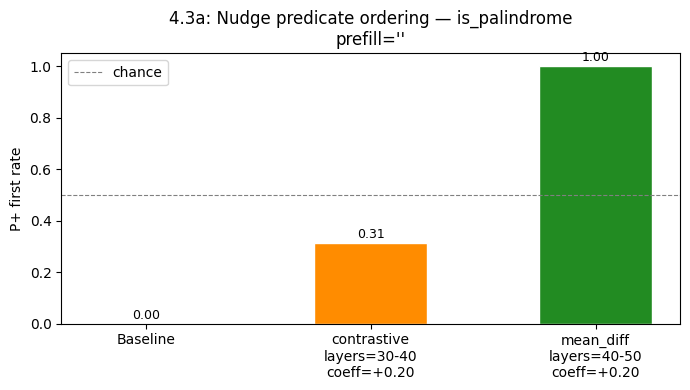

In [41]:
from matplotlib import pyplot as plt

# ── Visualise: bar chart (baseline vs best steered) ───────────────────────────
baseline_rate_4a = _rate(baseline_orders_4a, "p_plus_first")

# Find best steered rate across all configs for each direction type
best_steered = {}
for dir_type in ("contrastive", "mean_diff"):
    all_rates = [
        (rate, layer_tag, coeff)
        for layer_tag, coeff_dict in results_4a[dir_type].items()
        for coeff, rate in coeff_dict.items()
        if coeff > 0  # positive = toward P+
    ]
    if all_rates:
        best_rate, best_layer, best_coeff = max(all_rates, key=lambda x: x[0])
        best_steered[dir_type] = (best_rate, best_layer, best_coeff)

labels = ["Baseline"] + [
    f"{dt}\nlayers={v[1]}\ncoeff={v[2]:+.2f}"
    for dt, v in best_steered.items()
]
values = [baseline_rate_4a] + [v[0] for v in best_steered.values()]
colors = ["steelblue"] + ["darkorange", "forestgreen"][:len(best_steered)]

fig, ax = plt.subplots(figsize=(7, 4))
bars = ax.bar(labels, values, color=colors, edgecolor="white", width=0.5)
ax.set_ylim(0, 1.05)
ax.set_ylabel("P+ first rate")
ax.set_title(f"4.3a: Nudge predicate ordering — {PRED_NAME}\nprefill={PREFILL_4A!r}")
ax.axhline(0.5, color="gray", linewidth=0.8, linestyle="--", label="chance")
for bar, val in zip(bars, values):
    ax.text(bar.get_x() + bar.get_width() / 2, val + 0.02, f"{val:.2f}", ha="center", fontsize=9)
ax.legend()
plt.tight_layout()
plt.show()

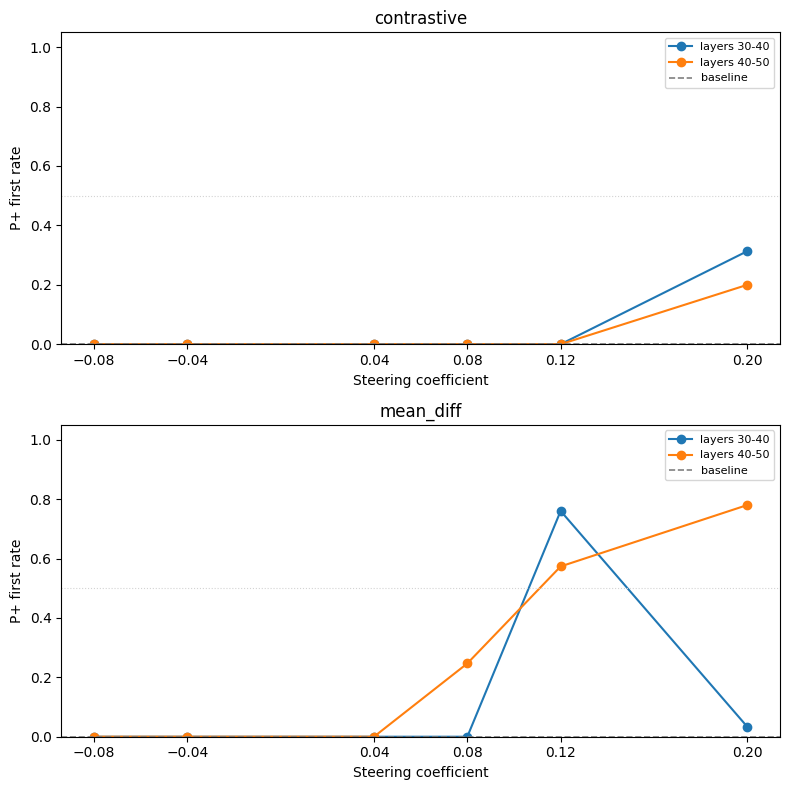

In [73]:
# ── Visualise: line plot of P+ first rate vs coeff per layer window ────────────
fig, axes = plt.subplots(2, 1, figsize=(8, 8), sharey=True)

for ax, dir_type in zip(axes, ["contrastive", "mean_diff"]):
    for layer_tag, coeff_dict in results_4a[dir_type].items():
        coeffs = sorted(coeff_dict.keys())
        rates  = [coeff_dict[c] for c in coeffs]
        ax.plot(coeffs, rates, marker="o", label=f"layers {layer_tag}")
    ax.axhline(baseline_rate_4a, color="gray", linewidth=1.2, linestyle="--", label="baseline")
    ax.axhline(0.5, color="lightgray", linewidth=0.8, linestyle=":")
    ax.set_xlabel("Steering coefficient")
    ax.set_ylabel("P+ first rate")
    ax.set_title(f"{dir_type}")
    ax.legend(fontsize=8)
    ax.set_ylim(0, 1.05)
    ax.set_xticks(coeffs)

# fig.suptitle(f"4.3a: P+ first rate vs coeff — {PRED_NAME}  (prefill={PREFILL_4A!r})", y=1.00)
plt.tight_layout()
plt.show()

In [63]:
SAVE_DIR = os.path.join(
    env_utils.DEFAULT_RESULTS_DIR,
    "multipred_probe",
    model_short_name,
    PRED_NAME,
    # "is_sorted"
)
rich_print(f"Loading directions from: {SAVE_DIR}")

# ── Load contrastive + mean-diff directions ───────────────────────────────────
contrastive_directions = torch.load(
    os.path.join(SAVE_DIR, "contrastive_directions.pt"),
    map_location="cuda:0",
    weights_only=False,
)
mean_diff_directions = torch.load(
    os.path.join(SAVE_DIR, "mean_diff_directions.pt"),
    map_location="cuda:0",
    weights_only=False,
)
rich_print(f"Contrastive directions loaded: {len(contrastive_directions)} layers")
rich_print(f"Mean-diff directions loaded:   {len(mean_diff_directions)} layers")

Loading directions from: /disk/u/arnab/Codes/Projects/goals/results/multipred_probe/Qwen2.5-Coder-32B-Instruct/is_palindrome

Contrastive directions loaded: 64 layers

Mean-diff directions loaded:   64 layers

In [64]:
contrastive_directions.keys()

dict_keys([0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33, 34, 35, 36, 37, 38, 39, 40, 41, 42, 43, 44, 45, 46, 47, 48, 49, 50, 51, 52, 53, 54, 55, 56, 57, 58, 59, 60, 61, 62, 63])

In [65]:
from src.functional import _apply_patch_to_state
from src.utils.typing import TokenizerOutput
import baukit
from typing import Literal


def remove_direction(h: torch.Tensor, d: torch.Tensor) -> torch.Tensor:
    """Remove the component of h along d. Handles both (D,) and (B, D) h."""
    d_unit = d / d.norm()
    proj = h @ d_unit  # (B,) or scalar
    return h - proj.unsqueeze(-1) * d_unit  # (B,1)*(D,) → (B,D) or scalar*(D,) → (D,)


def custom_generation_interface(
    steering_directions: dict[str, torch.Tensor],
    layer_range: tuple[int, int],
    coeff: float,
    on_pass: Literal["first", "all"],
) -> callable:
    def _steered_generation(
        mt: ModelandTokenizer,
        inputs: TokenizerOutput,
        max_new_tokens: int,
        do_sample: bool,
        **kwargs,
    ) -> torch.Tensor:
        if "patches" in kwargs:
            kwargs.pop("patches")
            logger.warning(
                "Ignoring 'patches' argument in generation_interface since we're using a custom hook-based approach."
            )

        layer_from, layer_to = layer_range

        def hook(output, layer):
            is_tuple = isinstance(output, tuple)
            actual = output[0] if is_tuple else output
            if actual.dim() == 2:
                actual = actual.unsqueeze(0)

            # Real tensor — shape is always concrete here.
            is_first_pass = actual.shape[1] > 1
            # print(f"{layer=} | {is_first_pass=}")

            should_apply = on_pass == "all" or (on_pass == "first" and is_first_pass)
            if should_apply:
                h_orig = actual[:, -1, :]  # (B, D) — no squeeze needed
                print(f"{layer=} | {actual.shape=} | {h_orig.shape=}")
                cur_layer_idx = int(layer.split(".")[2])
                steer_direction = (
                    steering_directions[cur_layer_idx]
                    .to(h_orig.dtype)
                    .to(h_orig.device)
                )

                if cur_layer_idx > layer_from:
                    nullify_direction = (
                        steering_directions[cur_layer_idx - 1]
                        .to(h_orig.dtype)
                        .to(h_orig.device)
                    )
                    h_orig = remove_direction(h_orig, nullify_direction)

                # Per-sample norm scaling: h_orig is (B, D)
                h_norms = h_orig.norm(dim=-1, keepdim=True)  # (B, 1)
                steer_patch = (
                    steer_direction * coeff * (h_norms / steer_direction.norm())
                )  # (B, D)
                h_patch = h_orig + steer_patch  # (B, D)

                _apply_patch_to_state(
                    current_state=actual, index=-1, patch=h_patch, strategy="replace"
                )

            return (actual,) + output[1:] if is_tuple else actual

        with baukit.TraceDict(
            module=mt._model,
            layers=[
                (mt.layer_name_format.format(li)) for li in range(layer_from, layer_to)
            ],
            edit_output=hook,
        ):
            out = mt._model.generate(
                **inputs,
                max_new_tokens=max_new_tokens,
                do_sample=do_sample,
                **kwargs,
            )

        return out.sequences if hasattr(out, "sequences") else out

    return _steered_generation


In [68]:
from src.tokens import prepare_input
from src.functional import PatchSpec, _generate_baukit
from collections import Counter
from scripts.causality.adversarial_persistence import (
    build_steer_patches,
    generate_and_evaluate,
    build_context_patches
)


################################
DIR_TYPE = "contrastive"  # or "mean_diff"
LAYER_FROM = 40
LAYER_TO = 50
COEFF = 0.08
################################

directions = (
    contrastive_directions if DIR_TYPE == "contrastive" else mean_diff_directions
)

tokenized = prepare_input(prompts=prompt_4a, tokenizer=mt)
n_tokens = tokenized.input_ids.shape[1]
hs = get_hs(
    mt=mt,
    input=tokenized,
    locations=[(mt.layer_name_format.format(li), -1) for li in range(mt.n_layer)]
    + [
        (mt.layer_name_format.format(li), tok_idx)
        for li in range(mt.n_layer)
        for tok_idx in range(n_tokens - 1)
    ],
)

patches = build_steer_patches(
    mt=mt,
    directions=directions,
    hs=hs_4a,
    layer_from=LAYER_FROM,
    layer_to=LAYER_TO,
    coeff=COEFF,
)

context_patches = build_context_patches(
    mt=mt,
    directions=directions,
    hs=hs,
    layer_from=LAYER_FROM,
    layer_to=LAYER_TO,
    coeff=COEFF,
    n_tokens=n_tokens,
)

# context_patches = []
# for li in range(LAYER_FROM, LAYER_TO):
#     layer_name = mt.layer_name_format.format(li)
#     h_orig = hs_4a[(layer_name, -1)]
#     goal_dir = directions[li].to(h_orig.dtype).to(h_orig.device)
#     scaled_goal_dir = goal_dir * COEFF * (h_orig.norm() / goal_dir.norm())
#     context_patches.extend(
#         [
#             PatchSpec(
#                 location=(layer_name, token_idx),
#                 patch=scaled_goal_dir,
#                 strategy="add",
#                 on_pass="first",
#             )
#             for token_idx in range(0, n_tokens - 1)
#             # for token_idx in range(-25, -1)
#         ]
#     )

patch_interface = custom_generation_interface(
    steering_directions=directions,
    layer_range=(LAYER_FROM, LAYER_TO),
    coeff=COEFF,
    on_pass="all",
)

steered_eval_results = generate_and_evaluate(
    mt=mt,
    sample=sample,
    prefill=PREFILL_4A,
    prompt=prompt_4a,
    n_generations=N_GENERATIONS_4A,
    patches=patches + context_patches,
    # patches=patches,
    label="steering",
    patch_interface="baukit",
    # patch_interface=patch_interface,
)


steered_outputs = [gen.lm_generation for gen in steered_eval_results.generations]
orders = Counter(predicate_order(g) for g in steered_outputs)
rate = _rate(orders, "p_plus_first")

rich_print(
    f"  [white][bold]{DIR_TYPE}[/bold][/white]: layers={LAYER_FROM}-{LAYER_TO} coeff={COEFF:+.2f} → P+ first={rate:.2f}"
)

2026-03-09 17:07:24 scripts.causality.adversarial_persistence DEBUG    Generating 200 samples (steering)...
2026-03-09 17:07:37 scripts.causality.adversarial_persistence DEBUG    Generation done. Evaluating 200 outputs...
2026-03-09 17:07:37 scripts.causality.adversarial_persistence DEBUG    Evaluation done: 200/200 passed (1.000)


contrastive: layers=40-50 coeff=+0.08 → P+ first=1.00

In [69]:
from src.goals.eval import pretty_print_eval_results
from copy import deepcopy

eval_results_filtered = deepcopy(steered_eval_results)
eval_results_filtered.generations = [
    gen for gen in eval_results_filtered.generations 
    # if gen.eval.verdict == "PASSED" # and predicate_order(gen.lm_generation) == "p_plus_first"
][:10]
pretty_print_eval_results(eval_results_filtered)

"""def is_lowercase_palindrome(s: str) -> bool:
    """Return True iff s consists entirely of lowercase characters and is a palindrome."""
    return """

                               Code Completion Results                               
┏━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━┓
┃ Prefill           ┃ Logic                           ┃ Verdict ┃ Unit Tests ┃ Logs ┃
┡━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━┩
│ steering_eval: "" │ " s == s[::-1] and s.islower()" │ PASSED  │            │      │
├───────────────────┼─────────────────────────────────┼─────────┼────────────┼──────┤
│ steering_eval: "" │ " s == s[::-1] and s.islower()" │ PASSED  │            │      │
├───────────────────┼─────────────────────────────────┼─────────┼────────────┼──────┤
│ steering_eval: "" │ " s == s[::-1] and s.islower()" │ PASSED  │            │      │
├───────────────────┼─────────────────────────────────┼─────────┼────────────┼──────┤
│ steering_eval: "" │ " s == s[::-1] and s.islower()" │ PASSED  │            │      │
├───────────────────┼─────────────────────────────────┼─────────┼────────────┼──────┤
│ steering_eval: "" │ " s == s[::-1] and s.islower()" │ PASSED  │            │      │
├───────────────────┼─────────────────────────────────┼─────────┼────────────┼──────┤
│ steering_eval: "" │ " s == s[::-1] and s.islower()" │ PASSED  │            │      │
├───────────────────┼─────────────────────────────────┼─────────┼────────────┼──────┤
│ steering_eval: "" │ " s == s[::-1] and s.islower()" │ PASSED  │            │      │
├───────────────────┼─────────────────────────────────┼─────────┼────────────┼──────┤
│ steering_eval: "" │ " s == s[::-1] and s.islower()" │ PASSED  │            │      │
├───────────────────┼─────────────────────────────────┼─────────┼────────────┼──────┤
│ steering_eval: "" │ " s == s[::-1] and s.islower()" │ PASSED  │            │      │
├───────────────────┼─────────────────────────────────┼─────────┼────────────┼──────┤
│ steering_eval: "" │ " s == s[::-1] and s.islower()" │ PASSED  │            │      │
└───────────────────┴─────────────────────────────────┴─────────┴────────────┴──────┘

Summary: 200/200 passed, 0/200 failed

In [70]:
p_plus_success = [
    gen for gen in steered_eval_results.generations 
    if gen.eval.verdict == "PASSED" and predicate_order(gen.lm_generation) == "p_plus_first"
]

p_neg_success = [
    gen for gen in steered_eval_results.generations 
    if gen.eval.verdict == "PASSED" and predicate_order(gen.lm_generation) == "p_minus_first"
]

rich_print(f"P+ success: {len(p_plus_success)} | P- success: {len(p_neg_success)}")

P+ success: 200 | P- success: 0

## 4.3b — Adversarial Prefill Persistence

**Protocol**: Take a standard single-predicate task (e.g., `is_palindrome`) where adversarial prefills (e.g., `1 +`, `(3`) confuse the model into failing. Steer with the goal direction trained from the multi-pred setup. Does the direction "remind" the model what it is supposed to do, improving pass rate?

In [74]:
from scripts.causality.results import AdversarialPersistenceResults

model_short_name = mt.name.split("/")[-1]
# ── 4.3b config ──────────────────────────────────────────────────────────────
PRED_NAME_4B   = PRED_NAME          # can override to pick a different predicate
RESULTS_DIR_4B = os.path.join(
    env_utils.DEFAULT_RESULTS_DIR, "multi_causality_context", model_short_name, PRED_NAME_4B
)
summary_path = os.path.join(RESULTS_DIR_4B, "summary.json")

rich_print(f"Loading results from: {summary_path}")
r = AdversarialPersistenceResults.load(summary_path)

rich_print(f"Predicate: {r.data['predicate_name']}")
rich_print(f"P+: {r.data['p_plus_description']}")
rich_print(f"N generations: {r.data['n_generations']}")
rich_print(f"Prefills in results: {list(r.data['prefill_results'].keys())}")

Loading results from: /disk/u/arnab/Codes/Projects/goals/results/multi_causality_context/Qwen2.5-Coder-32B-Instruct/is_palindrome/summary.json

Predicate: is_palindrome

P+: check whether s is a palindrome (s == s[::-1])

N generations: 200

Prefills in results: ['(3', '1 -', '1 +', 'not', 'not not', '5', '3 +', '0', '0 +']

In [75]:
from rich.table import Table

# ── Summary table: per-prefill baseline / best contrastive Δ / best mean_diff Δ ──
table = Table(title=f"4.3b Summary — {PRED_NAME_4B}", show_lines=True)
table.add_column("Prefill", style="bright_yellow", no_wrap=True)
table.add_column("Baseline", style="white", justify="right")
table.add_column("Contrastive", style="orange1", justify="right")
table.add_column("Δc (α, layer)", style="white", justify="right")
table.add_column("MeanDiff", style="bright_green", justify="right")
table.add_column("Δm (α, layer)", style="white", justify="right")

for pfx, pfr in r.data["prefill_results"].items():
    baseline = pfr["baseline_pass_rate"]
    bc = pfr.get("best_contrastive")
    bm = pfr.get("best_mean_diff")

    c_rate_str = f"{bc['pass_rate']:.3f}" if bc else "—"
    delta_c_str = f"{bc['pass_rate'] - baseline:+.3f}" if bc else "—"
    delta_c_str += f" ({float(bc['coeff']):.2f}, {bc['layer_idx']})" if bc else ""
    m_rate_str = f"{bm['pass_rate']:.3f}" if bm else "—"
    delta_m_str = f"{bm['pass_rate'] - baseline:+.3f}" if bm else "—"
    delta_m_str += f" ({float(bm['coeff']):.2f}, {bm['layer_idx']})" if bm else ""

    table.add_row(
        repr(pfx),
        f"{baseline:.3f}",
        c_rate_str,
        delta_c_str,
        m_rate_str,
        delta_m_str,
    )

console.print(table)

                              4.3b Summary — is_palindrome                               
┏━━━━━━━━━━━┳━━━━━━━━━━┳━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Prefill   ┃ Baseline ┃ Contrastive ┃     Δc (α, layer) ┃ MeanDiff ┃     Δm (α, layer) ┃
┡━━━━━━━━━━━╇━━━━━━━━━━╇━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ '(3'      │    0.410 │       0.595 │ +0.185 (0.02, 30) │    1.000 │ +0.590 (0.02, 25) │
├───────────┼──────────┼─────────────┼───────────────────┼──────────┼───────────────────┤
│ '1 -'     │    0.005 │       0.605 │ +0.600 (0.06, 35) │    0.390 │ +0.385 (0.06, 45) │
├───────────┼──────────┼─────────────┼───────────────────┼──────────┼───────────────────┤
│ '1 +'     │    0.265 │       0.690 │ +0.425 (0.10, 50) │    0.590 │ +0.325 (0.04, 50) │
├───────────┼──────────┼─────────────┼───────────────────┼──────────┼───────────────────┤
│ 'not'     │    1.000 │       1.000 │ +0.000 (0.02, 25) │    1.000 │ +0.000 (0.02, 25) │
├───────────┼──────────┼─────────────┼───────────────────┼──────────┼───────────────────┤
│ 'not not' │    0.000 │       0.400 │ +0.400 (0.06, 25) │    0.820 │ +0.820 (0.04, 25) │
├───────────┼──────────┼─────────────┼───────────────────┼──────────┼───────────────────┤
│ '5'       │    0.000 │       0.165 │ +0.165 (0.10, 50) │    0.000 │ +0.000 (0.02, 25) │
├───────────┼──────────┼─────────────┼───────────────────┼──────────┼───────────────────┤
│ '3 +'     │    0.000 │       0.160 │ +0.160 (0.08, 30) │    0.070 │ +0.070 (0.02, 40) │
├───────────┼──────────┼─────────────┼───────────────────┼──────────┼───────────────────┤
│ '0'       │    0.850 │       1.000 │ +0.150 (0.02, 25) │    1.000 │ +0.150 (0.02, 35) │
├───────────┼──────────┼─────────────┼───────────────────┼──────────┼───────────────────┤
│ '0 +'     │    0.475 │       0.880 │ +0.405 (0.12, 50) │    0.735 │ +0.260 (0.02, 50) │
└───────────┴──────────┴─────────────┴───────────────────┴──────────┴───────────────────┘

2026-03-09 17:10:03 matplotlib.colorbar DEBUG    locator: <matplotlib.ticker.AutoLocator object at 0x7f2b0c2df860>


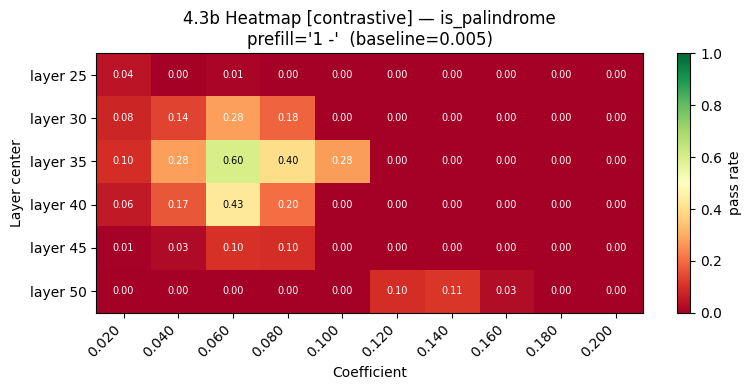

In [76]:
import numpy as np
from matplotlib import pyplot as plt

# ── Heatmap: pass_rate[layer][coeff] for contrastive, for a chosen prefill ───
HEATMAP_PREFILL = list(r.data["prefill_results"].keys())[1]  # change as needed
HEATMAP_DIR_TYPE = "contrastive"  # "contrastive" or "mean_diff"

by_layer = r.data["prefill_results"][HEATMAP_PREFILL]["by_layer"]
baseline_rate_hm = r.data["prefill_results"][HEATMAP_PREFILL]["baseline_pass_rate"]

# Collect all layer_idx and coeff keys
layer_keys = sorted(by_layer.keys(), key=int)
by_coeff_key = f"{HEATMAP_DIR_TYPE}_by_coeff"
all_coeffs = sorted(
    {c for ld in by_layer.values() for c in ld.get(by_coeff_key, {})},
    key=float,
)

# Build 2D array: rows = layers, cols = coeffs
matrix = np.full((len(layer_keys), len(all_coeffs)), np.nan)
for row_i, lk in enumerate(layer_keys):
    for col_j, ck in enumerate(all_coeffs):
        val = by_layer[lk].get(by_coeff_key, {}).get(ck)
        if val is not None:
            matrix[row_i, col_j] = val

fig, ax = plt.subplots(figsize=(max(8, len(all_coeffs) * 0.8), max(4, len(layer_keys) * 0.5 + 1)))
im = ax.imshow(matrix, aspect="auto", cmap="RdYlGn", vmin=0, vmax=1)
plt.colorbar(im, ax=ax, label="pass rate")
ax.set_xticks(range(len(all_coeffs)))
ax.set_xticklabels(all_coeffs, rotation=45, ha="right")
ax.set_yticks(range(len(layer_keys)))
ax.set_yticklabels([f"layer {lk}" for lk in layer_keys])
ax.set_xlabel("Coefficient")
ax.set_ylabel("Layer center")
ax.set_title(
    f"4.3b Heatmap [{HEATMAP_DIR_TYPE}] — {PRED_NAME_4B}\n"
    f"prefill={HEATMAP_PREFILL!r}  (baseline={baseline_rate_hm:.3f})"
)
# Annotate cells
for ri in range(len(layer_keys)):
    for ci in range(len(all_coeffs)):
        val = matrix[ri, ci]
        if not np.isnan(val):
            ax.text(ci, ri, f"{val:.2f}", ha="center", va="center", fontsize=7,
                    color="black" if 0.3 < val < 0.8 else "white")
plt.tight_layout()
plt.show()

2026-03-09 17:10:08 matplotlib.font_manager DEBUG    findfont: Matching sans\-serif:style=normal:variant=normal:weight=normal:stretch=normal:size=9.0.
2026-03-09 17:10:08 matplotlib.font_manager DEBUG    findfont: score(FontEntry(fname='/disk/u/arnab/miniconda3/envs/goals/lib/python3.12/site-packages/matplotlib/mpl-data/fonts/ttf/STIXGeneral.ttf', name='STIXGeneral', style='normal', variant='normal', weight=400, stretch='normal', size='scalable')) = 10.05
2026-03-09 17:10:08 matplotlib.font_manager DEBUG    findfont: score(FontEntry(fname='/disk/u/arnab/miniconda3/envs/goals/lib/python3.12/site-packages/matplotlib/mpl-data/fonts/ttf/DejaVuSerif-BoldItalic.ttf', name='DejaVu Serif', style='italic', variant='normal', weight=700, stretch='normal', size='scalable')) = 11.335
2026-03-09 17:10:08 matplotlib.font_manager DEBUG    findfont: score(FontEntry(fname='/disk/u/arnab/miniconda3/envs/goals/lib/python3.12/site-packages/matplotlib/mpl-data/fonts/ttf/DejaVuSans-Oblique.ttf', name='DejaVu

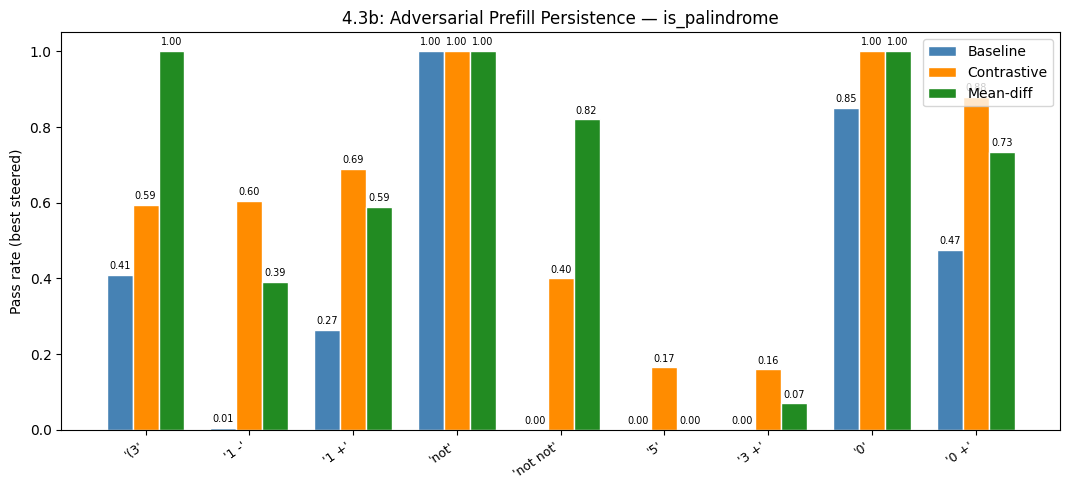

In [77]:
# ── Bar chart: for all prefills, grouped bars (baseline / contrastive / mean_diff) ──
pfx_list   = list(r.data["prefill_results"].keys())
baseline_vals     = [r.data["prefill_results"][p]["baseline_pass_rate"] for p in pfx_list]
contrastive_vals  = [
    (r.data["prefill_results"][p]["best_contrastive"] or {}).get("pass_rate", float("nan"))
    for p in pfx_list
]
mean_diff_vals    = [
    (r.data["prefill_results"][p]["best_mean_diff"] or {}).get("pass_rate", float("nan"))
    for p in pfx_list
]

x      = np.arange(len(pfx_list))
width  = 0.25
fig, ax = plt.subplots(figsize=(max(8, len(pfx_list) * 1.2), 5))

b1 = ax.bar(x - width, baseline_vals,    width, label="Baseline",    color="steelblue",   edgecolor="white")
b2 = ax.bar(x,          contrastive_vals, width, label="Contrastive", color="darkorange",  edgecolor="white")
b3 = ax.bar(x + width,  mean_diff_vals,   width, label="Mean-diff",   color="forestgreen", edgecolor="white")

ax.set_xticks(x)
ax.set_xticklabels([repr(p) for p in pfx_list], rotation=35, ha="right", fontsize=9)
ax.set_ylim(0, 1.05)
ax.set_ylabel("Pass rate (best steered)")
ax.set_title(f"4.3b: Adversarial Prefill Persistence — {PRED_NAME_4B}")
ax.legend()

for bar_group in [b1, b2, b3]:
    for bar in bar_group:
        h = bar.get_height()
        if not np.isnan(h):
            ax.text(bar.get_x() + bar.get_width() / 2, h + 0.01, f"{h:.2f}",
                    ha="center", va="bottom", fontsize=7)

plt.tight_layout()
plt.show()

In [126]:
from src.goals.functional import supports_chat_template, apply_chat_template
import copy

single_pred_sample = copy.deepcopy([
    d for d in single_pred_dataset if d.function_name == PRED_NAME
][0])
single_pred_sample.code = single_pred_sample.code.replace("s: str", "word: str")
single_pred_sample.code = single_pred_sample.code.replace("is_palindrome", "check_plndrome")
single_pred_sample.function_name = "check_plndrome"

rich_print(single_pred_sample)

# Use an inconsequential (unprefilled) prompt to see the model's natural preference
prefill = "1 -"
# prefill = ""
if supports_chat_template(mt):
    prompt = apply_chat_template(
        mt=mt,
        user_query=single_pred_sample.instruction.strip()
        if hasattr(single_pred_sample, "instruction")
        else "",
        incomplete_code=single_pred_sample.code + prefill,
    )
else:
    prompt = single_pred_sample.code + prefill

prefill_idx = prompt.index(prefill.strip())
rich_print(
    f'"[white]{prompt[:prefill_idx]}[/white][bright_yellow]{prompt[prefill_idx:]}[/bright_yellow]"'
)

IncompleteCodeSample(
    instruction='Write a function in python that checks if a string is a palindrome.\n\n',
    code='def check_plndrome(word: str) -> bool:\n    return True if ',
    unit_tests=[('racecar', True), ('hello', False), ('', True), ('a', True), ('ab', False), ('aba', True), ('abba', True)],
    prefills={'aligned': ['', '(', 's', 's ==', 's == s', 's[::', 's[::-1]', '(s', 'list(', 'list(s)'], 'adversarial': ['not', 'not (', 's +', '3', '1 +'], 'inconsequential': ['bool(', 'True and', 'False or', '0 +']},
    function_name='check_plndrome'
)

"<|im_start|>system
You are a helpful assistant proficient in programming. When completing code, ensure proper syntax and logical correctness. Make sure to have all codes inside the <code> </code> tags.<|im_end|>
<|im_start|>user
Write a function in python that checks if a string is a palindrome.<|im_end|>
<|im_start|>assistant
<code>
def check_plndrome(word: str) -> bool:
    return True if 1 -"

In [127]:
SAVE_DIR = os.path.join(
    env_utils.DEFAULT_RESULTS_DIR,
    "multipred_probe",
    model_short_name,
    PRED_NAME,
)
rich_print(f"Loading directions from: {SAVE_DIR}")

# ── Load contrastive + mean-diff directions ───────────────────────────────────
contrastive_directions = torch.load(
    os.path.join(SAVE_DIR, "contrastive_directions.pt"),
    map_location="cuda:0",
    weights_only=False,
)
mean_diff_directions = torch.load(
    os.path.join(SAVE_DIR, "mean_diff_directions.pt"),
    map_location="cuda:0",
    weights_only=False,
)
rich_print(f"Contrastive directions loaded: {len(contrastive_directions)} layers")
rich_print(f"Mean-diff directions loaded:   {len(mean_diff_directions)} layers")

Loading directions from: /disk/u/arnab/Codes/Projects/goals/results/multipred_probe/Qwen2.5-Coder-32B-Instruct/is_palindrome

Contrastive directions loaded: 64 layers

Mean-diff directions loaded:   64 layers

In [128]:
from scripts.causality.adversarial_persistence import (
    build_steer_patches,
    generate_and_evaluate,
)

baseline_eval_results = generate_and_evaluate(
    mt=mt,
    sample=single_pred_sample,
    prefill=prefill,
    prompt=prompt,
    n_generations=200,
    patches=None,
    label="baseline",
)

2026-03-09 17:42:11 scripts.causality.adversarial_persistence DEBUG    Generating 200 samples (baseline)...


2026-03-09 17:42:23 scripts.causality.adversarial_persistence DEBUG    Generation done. Evaluating 200 outputs...
2026-03-09 17:42:23 scripts.causality.adversarial_persistence DEBUG    Evaluation done: 0/200 passed (0.000)


In [129]:
from src.goals.eval import pretty_print_eval_results
from copy import deepcopy

eval_results_filtered = deepcopy(baseline_eval_results)
eval_results_filtered.generations = [
    gen for gen in eval_results_filtered.generations 
    # if gen.eval.verdict == "PASSED"
][:5]
pretty_print_eval_results(eval_results_filtered)

"""def check_plndrome(word: str) -> bool:
    return True if """

                                                                                Code Completion Results                                                                                 
┏━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━┓
┃ Prefill              ┃ Logic                                                                        ┃ Verdict ┃ Unit Tests                                                    ┃ Logs ┃
┡━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━┩
│ steering_eval: "1 -" │ "1 - word.find(word[::-1]) else False"                                       │ FAILED  │ check_plndrome(racecar)=True ✓                                │      │
│                      │                                                                              │         │ check_plndrome(hello)=True, expected False ✗                  │      │
│                      │                                                                              │         │ check_plndrome()=True ✓                                       │      │
│                      │                                                                              │         │ check_plndrome(a)=True ✓                                      │      │
│                      │                                                                              │         │ check_plndrome(ab)=True, expected False ✗                     │      │
│                      │                                                                              │         │ check_plndrome(aba)=True ✓                                    │      │
│                      │                                                                              │         │ check_plndrome(abba)=True ✓                                   │      │
├──────────────────────┼──────────────────────────────────────────────────────────────────────────────┼─────────┼───────────────────────────────────────────────────────────────┼──────┤
│ steering_eval: "1 -" │ "1 - word.find(word[::-1]) else False"                                       │ FAILED  │ check_plndrome(racecar)=True ✓                                │      │
│                      │                                                                              │         │ check_plndrome(hello)=True, expected False ✗                  │      │
│                      │                                                                              │         │ check_plndrome()=True ✓                                       │      │
│                      │                                                                              │         │ check_plndrome(a)=True ✓                                      │      │
│                      │                                                                              │         │ check_plndrome(ab)=True, expected False ✗                     │      │
│                      │                                                                              │         │ check_plndrome(aba)=True ✓                                    │      │
│                      │                                                                              │         │ check_plndrome(abba)=True ✓                                   │      │
├──────────────────────┼──────────────────────────────────────────────────────────────────────────────┼─────────┼───────────────────────────────────────────────────────────────┼──────┤
│ steering_eval: "1 -" │ "1 - len(word) == word[::-1] else False"                                     │ FAILED  │ check_plndrome(racecar)=False, expected True ✗                │      │
│                      │                                                                              │         │ c

Summary: 0/200 passed, 200/200 failed

In [130]:
from src.tokens import prepare_input
from src.functional import PatchSpec
from collections import Counter
from src.tokens import prepare_input
from src.functional import get_hs
from scripts.causality.adversarial_persistence import (
    build_steer_patches,
    generate_and_evaluate,
    build_context_patches
)

tokenized = prepare_input(prompts=prompt, tokenizer=mt)
n_tokens = tokenized.input_ids.shape[1]
hs = get_hs(
    mt=mt,
    input=tokenized,
    locations=[(mt.layer_name_format.format(li), -1) for li in range(mt.n_layer)]
    + [
        (mt.layer_name_format.format(li), tok_idx)
        for li in range(mt.n_layer)
        for tok_idx in range(n_tokens - 1)
    ],
)

################################
DIR_TYPE = "contrastive"  # or "mean_diff"
LAYER_FROM = 31
LAYER_TO = 40
COEFF = 0.06
N_GENERATIONS_4B = 200
################################

directions = (
    contrastive_directions if DIR_TYPE == "contrastive" else mean_diff_directions
)

patches = build_steer_patches(
    mt=mt,
    directions=directions,
    hs=hs,
    layer_from=LAYER_FROM,
    layer_to=LAYER_TO,
    coeff=COEFF,
)

prompt_tokenized = prepare_input(prompts=prompt, tokenizer=mt)
n_tokens = prompt_tokenized.input_ids.shape[1]

# context_patches = []
# for li in range(LAYER_FROM, LAYER_TO):
#     layer_name = mt.layer_name_format.format(li)
#     # h_orig = hs[(layer_name, -1)]
#     goal_dir = directions[li].to(h_orig.dtype).to(h_orig.device)
#     # scaled_goal_dir = goal_dir * COEFF * (h_orig.norm() / goal_dir.norm())
#     context_patches.extend(
#         [
#             PatchSpec(
#                 location=(layer_name, token_idx),
#                 patch=goal_dir
#                 * COEFF
#                 * (
#                     hs[(layer_name, token_idx)]
#                     .norm()
#                     .to(goal_dir.dtype)
#                     .to(goal_dir.device)
#                     / goal_dir.norm()
#                 ),
#                 strategy="add",
#                 on_pass="first",
#             )
#             for token_idx in range(0, n_tokens - 1)
#             # for token_idx in range(-25, -1)
#         ]
#     )

context_patches = build_context_patches(
    mt=mt,
    directions=directions,
    hs=hs,
    layer_from=LAYER_FROM,
    layer_to=LAYER_TO,
    coeff=COEFF,
    n_tokens=n_tokens,
)

steered_eval_results = generate_and_evaluate(
    mt=mt,
    sample=single_pred_sample,
    prefill=prefill,
    prompt=prompt,
    n_generations=N_GENERATIONS_4B,
    patches=patches + context_patches,
    # patches=patches,
    label=DIR_TYPE,
    patch_interface="baukit",
)

2026-03-09 17:42:27 scripts.causality.adversarial_persistence DEBUG    Generating 200 samples (contrastive)...
2026-03-09 17:42:38 scripts.causality.adversarial_persistence DEBUG    Generation done. Evaluating 200 outputs...
2026-03-09 17:42:38 scripts.causality.adversarial_persistence DEBUG    Evaluation done: 47/200 passed (0.235)


In [131]:
from src.goals.eval import pretty_print_eval_results
from copy import deepcopy

eval_results_filtered = deepcopy(steered_eval_results)
eval_results_filtered.generations = [
    gen for gen in eval_results_filtered.generations 
    if gen.eval.verdict == "PASSED"
][:10]
pretty_print_eval_results(eval_results_filtered)

"""def check_plndrome(word: str) -> bool:
    return True if """

                                                Code Completion Results                                                 
┏━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━┓
┃ Prefill              ┃ Logic                                                           ┃ Verdict ┃ Unit Tests ┃ Logs ┃
┡━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━┩
│ steering_eval: "1 -" │ "1 - 1 else word == word[::-1]"                                 │ PASSED  │            │      │
├──────────────────────┼─────────────────────────────────────────────────────────────────┼─────────┼────────────┼──────┤
│ steering_eval: "1 -" │ "1 - len(word) == 0 else False if word != word[::-1] else True" │ PASSED  │            │      │
├──────────────────────┼─────────────────────────────────────────────────────────────────┼─────────┼────────────┼──────┤
│ steering_eval: "1 -" │ "1 - 1 else word == word[::-1]"                                 │ PASSED  │            │      │
├──────────────────────┼─────────────────────────────────────────────────────────────────┼─────────┼────────────┼──────┤
│ steering_eval: "1 -" │ "1 - len(word) == -len(word) else word[::-1] == word"           │ PASSED  │            │      │
├──────────────────────┼─────────────────────────────────────────────────────────────────┼─────────┼────────────┼──────┤
│ steering_eval: "1 -" │ "1 - 1 else word == word[::-1]"                                 │ PASSED  │            │      │
├──────────────────────┼─────────────────────────────────────────────────────────────────┼─────────┼────────────┼──────┤
│ steering_eval: "1 -" │ "1 - len(word) == 1 else word[::-1] == word"                    │ PASSED  │            │      │
├──────────────────────┼─────────────────────────────────────────────────────────────────┼─────────┼────────────┼──────┤
│ steering_eval: "1 -" │ "1 - 1 else word == word[::-1]"                                 │ PASSED  │            │      │
├──────────────────────┼─────────────────────────────────────────────────────────────────┼─────────┼────────────┼──────┤
│ steering_eval: "1 -" │ "1 - len(word) == 1 else word == word[::-1]"                    │ PASSED  │            │      │
├──────────────────────┼─────────────────────────────────────────────────────────────────┼─────────┼────────────┼──────┤
│ steering_eval: "1 -" │ "1 - 1 else word == word[::-1]"                                 │ PASSED  │            │      │
├──────────────────────┼─────────────────────────────────────────────────────────────────┼─────────┼────────────┼──────┤
│ steering_eval: "1 -" │ "1 - 1 else word == word[::-1]"                                 │ PASSED  │            │      │
└──────────────────────┴─────────────────────────────────────────────────────────────────┴─────────┴────────────┴──────┘

Summary: 47/200 passed, 153/200 failed

## 4.3c — Induce Predicate in a unrelated context

**Protocol** (strongest test): Take an (a) arbitrary code generation context that has *no mention of the target predicate in its instructions* or (b) a function with a different predicate. Steer with the P+ goal direction. Check whether the model spontaneously introduces P+-related code (e.g., inserts a palindrome check where none was requested or an unrelated predicate is_vowel was requested).

**Claim**: If the direction encodes a generalizable intent to "do P+", steering should induce the model to insert P+-related code even in an unrelated context.

**Metric**: Frequency of P+ anchor tokens in steered vs baseline outputs.

In [113]:
for d in single_pred_dataset:
    print(d.function_name)

is_odd
is_even
is_non_negative
is_negative
is_zero
is_palindrome
is_empty
is_uppercase
is_digit_string
is_vowel
is_power_of_two
is_sorted
has_duplicates
all_same
is_anagram
is_perfect_square
has_unique_elements


In [114]:
for md in multi_dataset.groups:
    print(md.name)

has_unique_elements
is_anagram
is_palindrome
is_perfect_square
is_power_of_two
is_sorted


In [115]:
from src.goals.functional import supports_chat_template, apply_chat_template

# PRED_NAME = multi_dataset.groups[2].name
PRED_NAME = "is_sorted" 
logger.info(f"Selected predicate: {PRED_NAME}")


source_sample = [
    d for d in single_pred_dataset if d.function_name == PRED_NAME
][0]
rich_print(source_sample)

prefill = ""
if supports_chat_template(mt):
    source_prompt = apply_chat_template(
        mt=mt,
        user_query=source_sample.instruction.strip()
        if hasattr(source_sample, "instruction")
        else "",
        incomplete_code=source_sample.code + prefill,
    )
else:
    source_prompt = source_sample.code + prefill

rich_print(
    f'"[white]{source_prompt}[/white]"'
)

2026-03-16 12:26:40 __main__ INFO     Selected predicate: is_sorted


IncompleteCodeSample(
    instruction='Write a function in python that checks if a list of integers is sorted in non-decreasing order.\n\n',
    code='def is_sorted(lst: list) -> bool:\n    return True if ',
    unit_tests=[([], True), ([1], True), ([1, 2, 3], True), ([3, 2, 1], False), ([1, 1, 1], True), ([1, 3, 2], False)],
    prefills={'aligned': ['', '(', 'lst', 'lst ==', 'lst == sorted(', 'sorted(', 'sorted(lst)', 'all(', '(lst'], 'adversarial': ['not', 'not (', 'lst +', '3', '1 +', 'any('], 'inconsequential': ['len(', 'bool(', 'True and', 'False or']},
    function_name='is_sorted'
)

"<|im_start|>system
You are a helpful assistant proficient in programming. When completing code, ensure proper syntax and logical correctness. Make sure to have all codes inside the <code> </code> tags.<|im_end|>
<|im_start|>user
Write a function in python that checks if a list of integers is sorted in non-decreasing order.<|im_end|>
<|im_start|>assistant
<code>
def is_sorted(lst: list) -> bool:
    return True if "

In [119]:
import random
import copy

# destination_sample = random.choice([
#     d for d in single_pred_dataset if d.function_name != PRED_NAME
# ])
# DEST_PRED_NAME = "is_uppercase"
DEST_PRED_NAME = "has_unique_elements"
destination_sample = copy.deepcopy([
    d for d in single_pred_dataset if d.function_name == DEST_PRED_NAME
][0])
destination_sample.code=destination_sample.code.replace("s: str", "word: str")

rich_print(destination_sample)

if supports_chat_template(mt):
    destination_prompt = apply_chat_template(
        mt=mt,
        user_query=destination_sample.instruction.strip()
        if hasattr(destination_sample, "instruction")
        else "",
        incomplete_code=destination_sample.code + prefill,
    )
else:
    destination_prompt = destination_sample.code + prefill

rich_print(
    f'"[white]{destination_prompt}[/white]"'
)


IncompleteCodeSample(
    instruction='Write a function in python that checks if all elements in a list are unique.\n\n',
    code='def has_unique_elements(lst: list) -> bool:\n    return True if ',
    unit_tests=[([1, 2, 3], True), ([1, 1, 2], False), ([], True), ([1], True), ([3, 1, 2], True), ([1, 2, 1], False), (['a', 'b', 'c'], True), (['a', 'a'], False)],
    prefills={'aligned': ['', '(', 'len(', 'len(lst)', 'len(lst) ==', 'set(', 'set(lst)'], 'adversarial': ['not', 'not (', 'lst +', '3', '1 +', 'any('], 'inconsequential': ['bool(', 'True and', 'False or', '0 +']},
    function_name='has_unique_elements'
)

"<|im_start|>system
You are a helpful assistant proficient in programming. When completing code, ensure proper syntax and logical correctness. Make sure to have all codes inside the <code> </code> tags.<|im_end|>
<|im_start|>user
Write a function in python that checks if all elements in a list are unique.<|im_end|>
<|im_start|>assistant
<code>
def has_unique_elements(lst: list) -> bool:
    return True if "

In [120]:
model_short_name = MODEL_NAME.split("/")[-1]
SAVE_DIR = os.path.join(
    env_utils.DEFAULT_RESULTS_DIR,
    "multipred_probe",
    model_short_name,
    PRED_NAME,
)
rich_print(f"Loading directions from: {SAVE_DIR}")

# ── Load contrastive + mean-diff directions ───────────────────────────────────
contrastive_directions = torch.load(
    os.path.join(SAVE_DIR, "contrastive_directions.pt"),
    map_location="cuda:0",
    weights_only=False,
)
mean_diff_directions = torch.load(
    os.path.join(SAVE_DIR, "mean_diff_directions.pt"),
    map_location="cuda:0",
    weights_only=False,
)
rich_print(f"Contrastive directions loaded: {len(contrastive_directions)} layers")
rich_print(f"Mean-diff directions loaded:   {len(mean_diff_directions)} layers")

Loading directions from: /disk/u/arnab/Codes/Projects/goals/results/multipred_probe/Qwen2.5-Coder-32B-Instruct/is_sorted

Contrastive directions loaded: 64 layers

Mean-diff directions loaded:   64 layers

In [121]:
from scripts.causality.adversarial_persistence import (
    build_steer_patches,
    generate_and_evaluate,
    build_context_patches
)

from src.goals.eval import pretty_print_eval_results
from copy import deepcopy

baseline_eval_results = generate_and_evaluate(
    mt=mt,
    sample=destination_sample,
    prefill=prefill,
    prompt=destination_prompt,
    n_generations=200,
    patches=None,
    label="baseline",
)

eval_results_filtered = deepcopy(baseline_eval_results)
eval_results_filtered.generations = [
    gen for gen in eval_results_filtered.generations 
    # if gen.eval.verdict == "PASSED"
][:20]
pretty_print_eval_results(eval_results_filtered)

2026-03-16 12:27:49 scripts.causality.adversarial_persistence DEBUG    Generating 200 samples (baseline)...
2026-03-16 12:28:31 scripts.causality.adversarial_persistence DEBUG    Generation done. Evaluating 200 outputs...
2026-03-16 12:28:31 scripts.causality.adversarial_persistence DEBUG    Evaluation done: 200/200 passed (1.000)


"""def has_unique_elements(lst: list) -> bool:
    return True if """

                                   Code Completion Results                                   
┏━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━┓
┃ Prefill           ┃ Logic                                   ┃ Verdict ┃ Unit Tests ┃ Logs ┃
┡━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━┩
│ steering_eval: "" │ " len(lst) == len(set(lst)) else False" │ PASSED  │            │      │
├───────────────────┼─────────────────────────────────────────┼─────────┼────────────┼──────┤
│ steering_eval: "" │ " len(lst) == len(set(lst)) else False" │ PASSED  │            │      │
├───────────────────┼─────────────────────────────────────────┼─────────┼────────────┼──────┤
│ steering_eval: "" │ " len(lst) == len(set(lst)) else False" │ PASSED  │            │      │
├───────────────────┼─────────────────────────────────────────┼─────────┼────────────┼──────┤
│ steering_eval: "" │ " len(lst) == len(set(lst)) else False" │ PASSED  │            │      │
├───────────────────┼─────────────────────────────────────────┼─────────┼────────────┼──────┤
│ steering_eval: "" │ " len(lst) == len(set(lst)) else False" │ PASSED  │            │      │
├───────────────────┼─────────────────────────────────────────┼─────────┼────────────┼──────┤
│ steering_eval: "" │ " len(lst) == len(set(lst)) else False" │ PASSED  │            │      │
├───────────────────┼─────────────────────────────────────────┼─────────┼────────────┼──────┤
│ steering_eval: "" │ " len(lst) == len(set(lst)) else False" │ PASSED  │            │      │
├───────────────────┼─────────────────────────────────────────┼─────────┼────────────┼──────┤
│ steering_eval: "" │ " len(lst) == len(set(lst)) else False" │ PASSED  │            │      │
├───────────────────┼─────────────────────────────────────────┼─────────┼────────────┼──────┤
│ steering_eval: "" │ " len(lst) == len(set(lst)) else False" │ PASSED  │            │      │
├───────────────────┼─────────────────────────────────────────┼─────────┼────────────┼──────┤
│ steering_eval: "" │ " len(lst) == len(set(lst)) else False" │ PASSED  │            │      │
├───────────────────┼─────────────────────────────────────────┼─────────┼────────────┼──────┤
│ steering_eval: "" │ " len(lst) == len(set(lst)) else False" │ PASSED  │            │      │
├───────────────────┼─────────────────────────────────────────┼─────────┼────────────┼──────┤
│ steering_eval: "" │ " len(lst) == len(set(lst)) else False" │ PASSED  │            │      │
├───────────────────┼─────────────────────────────────────────┼─────────┼────────────┼──────┤
│ steering_eval: "" │ " len(lst) == len(set(lst)) else False" │ PASSED  │            │      │
├───────────────────┼─────────────────────────────────────────┼─────────┼────────────┼──────┤
│ steering_eval: "" │ " len(lst) == len(set(lst)) else False" │ PASSED  │            │      │
├───────────────────┼─────────────────────────────────────────┼─────────┼────────────┼──────┤
│ steering_eval: "" │ " len(lst) == len(set(lst)) else False" │ PASSED  │            │      │
├───────────────────┼─────────────────────────────────────────┼─────────┼────────────┼──────┤
│ steering_eval: "" │ " len(lst) == len(set(lst)) else False" │ PASSED  │            │      │
├───────────────────┼─────────────────────────────────────────┼─────────┼────────────┼──────┤
│ steering_eval: "" │ " len(lst) == len(set(lst)) else False" │ PASSED  │            │      │
├───────────────────┼─────────────────────────────────────────┼─────────┼────────────┼──────┤
│ steering_eval: "" │ " len(lst) == len(set(lst)) else False" │ PASSED  │            │      │
├───────────────────┼─────────────────────────────────────────┼─────────┼────────────┼──────┤
│ steering_eval: "" │ " len(lst) == len(set(lst)) else False" │ PASSED  │            │      │
├───────────────────┼─────────────────────────────────────────┼─────────┼────────────┼──────┤
│ steering_eval: "" │ " len(lst) == len(set(lst)) el

Summary: 200/200 passed, 0/200 failed

In [122]:
rich_print(f"[white]{destination_prompt}[/white]")

<|im_start|>system
You are a helpful assistant proficient in programming. When completing code, ensure proper syntax and logical correctness. Make sure to have all codes inside the <code> </code> tags.<|im_end|>
<|im_start|>user
Write a function in python that checks if all elements in a list are unique.<|im_end|>
<|im_start|>assistant
<code>
def has_unique_elements(lst: list) -> bool:
    return True if 

In [139]:
from src.tokens import prepare_input
from src.functional import PatchSpec
from collections import Counter
from src.tokens import prepare_input
from src.functional import get_hs, generate_with_patch
import copy

tokenized = prepare_input(prompts=destination_prompt, tokenizer=mt)
n_tokens = tokenized.input_ids.shape[1]
hs = get_hs(
    mt=mt,
    input=tokenized,
    locations=[(mt.layer_name_format.format(li), -1) for li in range(mt.n_layer)]
    + [
        (mt.layer_name_format.format(li), tok_idx)
        for li in range(mt.n_layer)
        for tok_idx in range(n_tokens - 1)
    ],
)

################################
DIR_TYPE = "contrastive"  # or "mean_diff"
LAYER_FROM = 31
LAYER_TO = 40
COEFF = 0.3
N_GENERATIONS_4C = 200
################################

directions = (
    contrastive_directions if DIR_TYPE == "contrastive" else mean_diff_directions
)

patches = build_steer_patches(
    mt=mt,
    directions=directions,
    hs=hs,
    layer_from=LAYER_FROM,
    layer_to=LAYER_TO,
    coeff=COEFF,
)

context_patches = build_context_patches(
    mt=mt,
    directions=directions,
    hs=hs,
    layer_from=LAYER_FROM,
    layer_to=LAYER_TO,
    coeff=COEFF,
    n_tokens=n_tokens,
)

steered_outputs = generate_with_patch(
    mt = mt,
    inputs = destination_prompt,
    patches = patches + context_patches,
    n_gen_per_prompt=N_GENERATIONS_4C,
    max_new_tokens=64,
    patch_interface="baukit",
    remove_prefix=True
)

In [140]:
from src.goals.data import Code, CodeGenerations
from scripts.causality.adversarial_persistence import run_evaluation_timed

patch_sample = copy.deepcopy(source_sample)
patch_sample.function_name = destination_sample.function_name
patch_sample.code = destination_sample.code

eval_sample = patch_sample
# eval_sample = destination_sample
rich_print(eval_sample)

generations = CodeGenerations(
    sample=eval_sample,
    generations=[
        Code(
            prefill=prefill,
            prefill_type="steering_eval",
            full_prompt=destination_prompt,
            lm_generation=gen,
        )
        for gen in steered_outputs
    ],
)

eval_context = {"label": "cross-transfer", "prefill": ""}
eval_results = run_evaluation_timed(
    result=generations,
    function_name=eval_sample.function_name,
    code_stop_tag="</code>",
    eval_timeout=5,
    context=eval_context,
    eval_timeout_log = None
)

pass_rate = eval_results.summary.pass_count / eval_results.summary.total
logger.debug(
    f"Evaluation done: {eval_results.summary.pass_count}/{eval_results.summary.total} "
    f"passed ({pass_rate:.3f})"
)

IncompleteCodeSample(
    instruction='Write a function in python that checks if a list of integers is sorted in non-decreasing order.\n\n',
    code='def has_unique_elements(lst: list) -> bool:\n    return True if ',
    unit_tests=[([], True), ([1], True), ([1, 2, 3], True), ([3, 2, 1], False), ([1, 1, 1], True), ([1, 3, 2], False)],
    prefills={'aligned': ['', '(', 'lst', 'lst ==', 'lst == sorted(', 'sorted(', 'sorted(lst)', 'all(', '(lst'], 'adversarial': ['not', 'not (', 'lst +', '3', '1 +', 'any('], 'inconsequential': ['len(', 'bool(', 'True and', 'False or']},
    function_name='has_unique_elements'
)

2026-03-16 12:35:21 __main__ DEBUG    Evaluation done: 0/200 passed (0.000)


In [141]:
from src.goals.eval import pretty_print_eval_results
from copy import deepcopy

eval_results_filtered = deepcopy(eval_results)
eval_results_filtered.generations = [
    gen for gen in eval_results_filtered.generations 
    # if gen.eval.verdict == "PASSED"
][:10]
pretty_print_eval_results(eval_results_filtered)

"""def has_unique_elements(lst: list) -> bool:
    return True if """

                                                                                        Code Completion Results                                                                                         
┏━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┓
┃ Prefill           ┃ Logic                                                                    ┃ Verdict      ┃ Unit Tests ┃ Logs                                                                      ┃
┡━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┩
│ steering_eval: "" │ "3 is not specified)"                                                    │ SYNTAX_ERROR │            │ unmatched ')' (<string>, line 2)                                          │
│                   │                                                                          │              │            │ def has_unique_elements(lst: list) -> bool:                               │
│                   │                                                                          │              │            │     return True if 3 is not specified)                                    │
├───────────────────┼──────────────────────────────────────────────────────────────────────────┼──────────────┼────────────┼───────────────────────────────────────────────────────────────────────────┤
│ steering_eval: "" │ "3rd element is not less than the first one. You can use any of these    │ SYNTAX_ERROR │            │ invalid decimal literal (<string>, line 2)                                │
│                   │ algorithms to sort the array and then you can select the third element   │              │            │ def has_unique_elements(lst: list) -> bool:                               │
│                   │ as a goal. The goal is to sort the array and then you can select the     │              │            │     return True if 3rd element is not less than the first one. You can    │
│                   │ third element to be selected. This is a simple algorithm to sort the     │              │            │ use any of these algorithms to sort the array and then you can select the │
│                   │ array."                                                                  │              │            │ third element as a goal. The goal is to sort the array and then you can   │
│                   │                                                                          │              │            │ select the third element to be selected. This is a simple algorithm to    │
│                   │                                                                          │              │            │ sort the array.                                                           │
├───────────────────┼──────────────────────────────────────────────────────────────────────────┼──────────────┼────────────┼───────────────────────────────────────────────────────────────────────────┤
│ steering_eval: "" │ "3rd element is specified) to any other element. You can use a different │ SYNTAX_ERROR │            │ invalid decimal literal (<string>, line 2)                                │
│                   │ algorithm to sort the array. You can then use it to sort the array."     │              │            │ def has_unique_elements(lst: list) -> bool:                               │
│                   │                                                                          │              │            │     return True if 3rd element is specified) to any other element. You    │
│                   │                                                                          │              │            │ can use a different algorithm to sort the array. You can

Summary: 0/200 passed, 200/200 failed

In [126]:
from src.tokens import prepare_input
from src.functional import PatchSpec, get_hs, generate_with_patch

truncated_prompt = destination_prompt.replace("return True if", '""" Check if')
truncated_prompt = truncated_prompt.replace("s: str", "word: str")
rich_print(f"[white]{truncated_prompt}[/white]")

truncated_prompt_tokenized = prepare_input(prompts=truncated_prompt, tokenizer=mt)
n_tokens_truncated = truncated_prompt_tokenized.input_ids.shape[1]

base_trunc_outputs = generate_with_patch(
    mt = mt,
    inputs = truncated_prompt,
    patches = None,
    n_gen_per_prompt=20,
    max_new_tokens=64,
    patch_interface="baukit",
    remove_prefix=True
)

<|im_start|>system
You are a helpful assistant proficient in programming. When completing code, ensure proper syntax and logical correctness. Make sure to have all codes inside the <code> </code> tags.<|im_end|>
<|im_start|>user
Write a function in python that checks if all elements in a list are unique.<|im_end|>
<|im_start|>assistant
<code>
def has_unique_elements(lst: list) -> bool:
    """ Check if 

In [127]:
base_trunc_outputs

[' all elements in the list are unique.\n\n    Args:\n        lst (list): The list to check for uniqueness of elements.\n\n    Returns:\n        bool: True if all elements are unique, False otherwise.\n    """\n    return len(lst) == len(set(lst))\n</code>\n\nThis function works by converting the list into',
 ' all elements in a list are unique """\n    seen = set()\n    for element in lst:\n        if element in seen:\n            return False\n        seen.add(element)\n    return True\n\n# Example usage:\nprint(has_unique_elements([1, 2, 3, 4]))  # Output: True\n',
 ' all elements in a list are unique.\n\n    Args:\n        lst (list): The list to check for uniqueness of elements.\n\n    Returns:\n        bool: True if all elements are unique, False otherwise.\n    """\n    seen = set()\n    for element in lst:\n        if element in seen:\n            return False\n',
 ' all elements in the list are unique """\n    return len(lst) == len(set(lst))\n\n# Example usage:\nexample_list 

In [135]:
from scripts.causality.adversarial_persistence import (
    build_steer_patches,
    generate_and_evaluate,
    build_context_patches
)

n_tokens = truncated_prompt_tokenized.input_ids.shape[1]
hs = get_hs(
    mt=mt,
    input=truncated_prompt_tokenized,
    locations=[(mt.layer_name_format.format(li), -1) for li in range(mt.n_layer)]
    + [
        (mt.layer_name_format.format(li), tok_idx)
        for li in range(mt.n_layer)
        for tok_idx in range(n_tokens_truncated - 1)
    ],
)

################################
DIR_TYPE = "contrastive"  # or "mean_diff"
LAYER_FROM = 31
LAYER_TO = 40
COEFF = 0.3
################################

directions = (
    contrastive_directions if DIR_TYPE == "contrastive" else mean_diff_directions
)

patches = build_steer_patches(
    mt=mt,
    directions=directions,
    hs=hs,
    layer_from=LAYER_FROM,
    layer_to=LAYER_TO,
    coeff=COEFF,
)

context_patches = build_context_patches(
    mt=mt,
    directions=directions,
    hs=hs,
    layer_from=LAYER_FROM,
    layer_to=LAYER_TO,
    coeff=COEFF,
    n_tokens=n_tokens_truncated,
)


In [136]:
steered_trunc_outputs = generate_with_patch(
    mt = mt,
    inputs = truncated_prompt,
    patches = patches + context_patches,
    n_gen_per_prompt=20,
    max_new_tokens=64,
    patch_interface="baukit",
    remove_prefix=True
)

In [137]:
steered_trunc_outputs

["10-element array is sorted\n        return true if it's sorted\n        return false\n        You can sort any number of elements to create a sorted array\n        then you can sort the array back to the original\n        You can sort any number of elements to create a sorted array\n        You can sort the",
 '100 randomly-generated integers to sort them. You can use this to sort the array of integers. You can use it to sort the array of integers. You can use it to sort the array of integers. You can use it to sort the array of integers. You can use it to sort the array of integers',
 '3-element tuple is specified")\n        return the first element of the tuple\n- returns the last element of the tuple\n- You can specify multiple tuples to sort by the first element and then you can specify multiple tuples to sort by the first element and then you can specify multiple tuples to sort by the first element"))\n-',
 ')))\n  return a sequence of numbers from 1 to n\n- You can sort them by

In [138]:
rich_print(f"[white]{truncated_prompt}[/white]")

<|im_start|>system
You are a helpful assistant proficient in programming. When completing code, ensure proper syntax and logical correctness. Make sure to have all codes inside the <code> </code> tags.<|im_end|>
<|im_start|>user
Write a function in python that checks if all elements in a list are unique.<|im_end|>
<|im_start|>assistant
<code>
def has_unique_elements(lst: list) -> bool:
    """ Check if 

## Logit Lens

In [212]:
SAVE_DIR = os.path.join(
    env_utils.DEFAULT_RESULTS_DIR,
    "multipred_probe",
    model_short_name,
    # PRED_NAME,
    "is_sorted"
)
rich_print(f"Loading directions from: {SAVE_DIR}")

# ── Load contrastive + mean-diff directions ───────────────────────────────────
contrastive_directions = torch.load(
    os.path.join(SAVE_DIR, "contrastive_directions.pt"),
    map_location="cuda:0",
    weights_only=False,
)
mean_diff_directions = torch.load(
    os.path.join(SAVE_DIR, "mean_diff_directions.pt"),
    map_location="cuda:0",
    weights_only=False,
)
rich_print(f"Contrastive directions loaded: {len(contrastive_directions)} layers")
rich_print(f"Mean-diff directions loaded:   {len(mean_diff_directions)} layers")

Loading directions from: /disk/u/arnab/Codes/Projects/goals/results/multipred_probe/Qwen2.5-Coder-32B-Instruct/is_sorted

Contrastive directions loaded: 64 layers

Mean-diff directions loaded:   64 layers

In [213]:
from src.functional import logit_lens

DIR_TYPE = "contrastive"
directions = (
    contrastive_directions if DIR_TYPE == "contrastive" else mean_diff_directions
)

for layer_idx in range(0, mt.n_layer, 5):
    h = hs[(mt.layer_name_format.format(layer_idx), -1)]
    direction = directions[layer_idx].to(mt.dtype).to(h.device)
    direction = direction * (h.norm() / direction.norm())
    ll_goal = logit_lens(
        mt=mt,
        h=direction,
    )
    print(f"{layer_idx}: {[str(pred.token) for pred in ll_goal]}")

0: ['ANGLES', '�', ' unders', ' над', '깨']
5: ['恺', 'アウ', 'toMatch', '敬畏', 'ApiClient']
10: [' hon', '利用您的', '服从', 'peare', 'claimer']
15: ['Reviewer', ' thr', '塑', 'aji', '吞']
20: [' нару', 'avings', '膨', 'רה', 'eren']
25: [' Urban', ' Sem', 'ogui', 'วน', '跋']
30: ['clave', '倒', 'วน', 'ali', '一把']
35: [' THR', 'eneg', '利用您的', 'Baseline', 'erce']
40: ['lat', 'ambi', 'dek', 'astes', '_inverse']
45: ['逆', 'verts', '蛙', ' mandates', '.itemView']
50: [' uden', '我会', 'lp', '关口', 'ools']
55: ['我会', '丧失', 'agedList', 'ведите', 'wt']
60: ['草', ' OVERRIDE', '_DEN', ' pairwise', 'RPC']


In [207]:
from src.functional import patchscope

DIR_TYPE = "contrastive"
directions = (
    contrastive_directions if DIR_TYPE == "contrastive" else mean_diff_directions
)

for layer_idx in range(0, mt.n_layer, 5):
    h = hs[(mt.layer_name_format.format(layer_idx), -1)]
    direction = directions[layer_idx].to(mt.dtype).to(h.device)
    direction = direction * (h.norm() / direction.norm())
    ll_goal = patchscope(
        mt=mt,
        h=direction,
    )
    print(f"{layer_idx}: {[str(pred.token) for pred in ll_goal]}")

0: [' ', ' fridge', ' iPhone', ' chair', ' Earth']
5: [' ', ' E', ' iPhone', ' A', ' S']
10: [' os', ' s', ' iOS', ' pizza', ' ']
15: [' ', ' h', ' HMS', ' rms', ' H']
20: [' ', " '", ' r', ' R', " '\n"]
25: [' ', ' Q', ' R', " '\n", ' q']
30: [' ', ' R', ' REM', ' RM', ' M']
35: [' ', " '\n", ' "\n', ' \n', " ''\n"]
40: [' ', " '\n", " '", ' <\n', ' \n']
45: [" '\n", ' ', " '", " ''\n", " '\n\n"]
50: [' ', ' \n', ' |\n', ' `', " '\n"]
55: [' ', ' ""\n', " ''\n", ' -\n', ' "\n']
60: [' ', ' LL', ' l', ' ll', ' a']
